In [2]:
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.gridspec as gridspec
import pickle as pickle
import os
import import_ipynb
from matplotlib.patches import FancyArrowPatch
import ipynb.fs.full.ssiProjectModule as ssiMod
import importlib as imp
imp.reload(ssiMod)
import itertools
from matplotlib.collections import LineCollection as LC

In [3]:
theta_step = 2

exp_dir = 'C:/Users/Carlo PARIS/00PhD Code/CoSyne/'

main_dir = 'C:/Users/Carlo PARIS/00PhD Code/'
dat_dir_in = 'C:/Users/Carlo PARIS/00PhD Code/0Paper plots/Figure1/'
dat_dir_out = 'C:/Users/Carlo PARIS/00PhD Code/0Paper plots/Figure2/'
title = f'Stretch_BioQuads_multiplied_w_mean_g__theta_step={theta_step}_original_g_20240509_AREA.pkl'

with open(dat_dir_in+title, 'rb') as rick:
    data_dict = pickle.load(rick)
bio_idx = np.where(data_dict['all_multipliers']==1.)[0][0]
print(data_dict.keys())

dict_keys(['all_multipliers', 'all_quad_pars', 'all_quad_tc', 'all_ssis', 'all_quad_fwhm', 'exp_quad_list', 'all_quad_vm_fit_pars', 'all_quad_raw_mean_tcs', 'all_quad_raw_mean_stds', 'original_cell_idx_quads', 'is_bio_quad'])


In [4]:
colors=['blue', 'green','red', 'gold' ]
example_quads = [201,125]
stim = np.arange(0,360,2)
ticksize = 15
labelsize = 20
textsize = 25

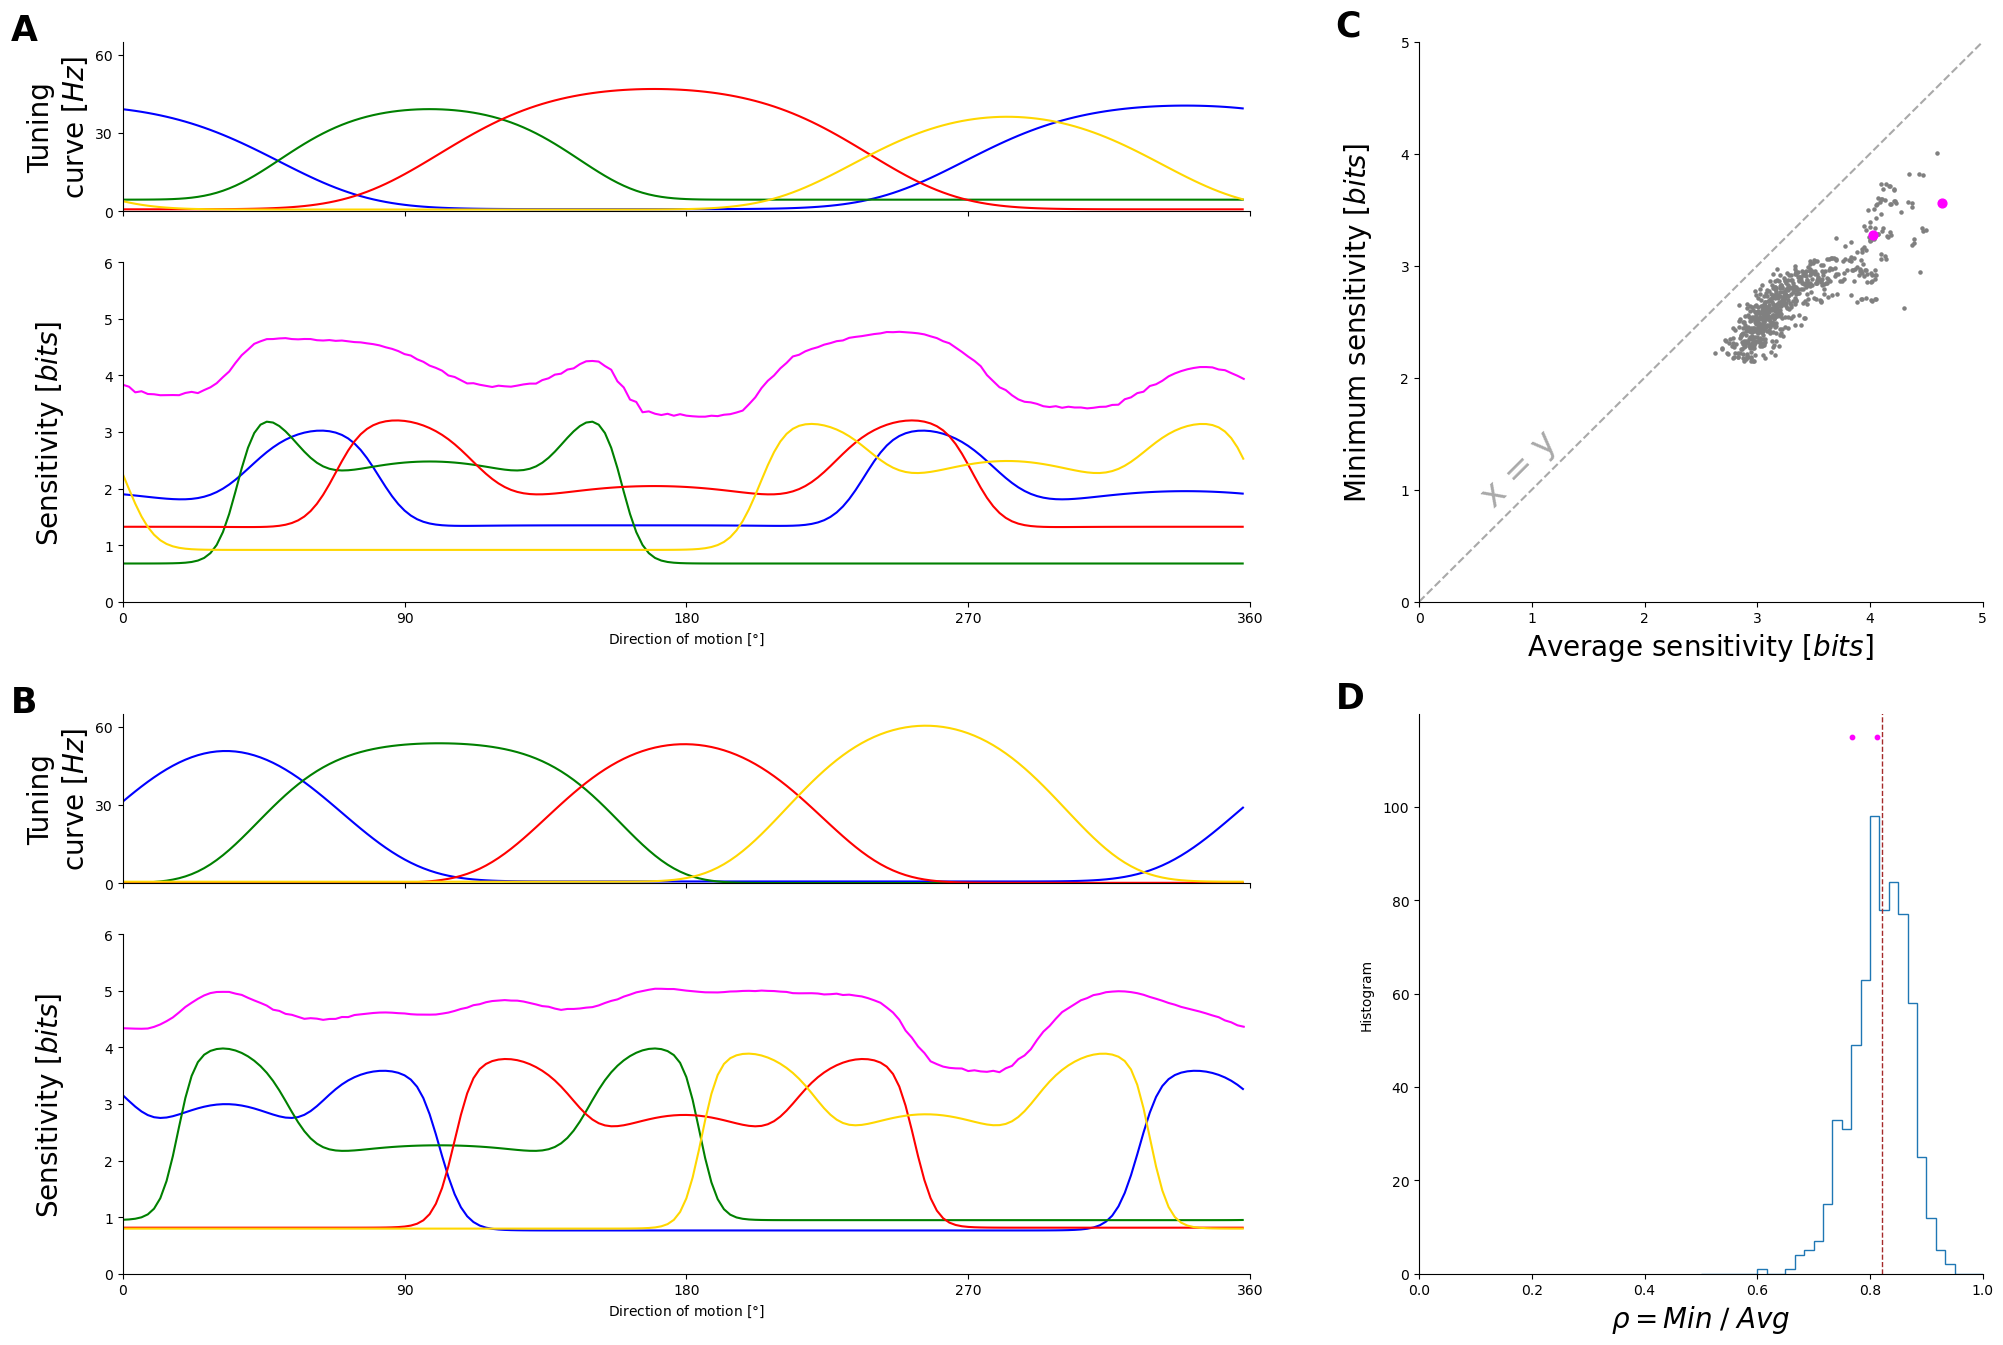

In [4]:
fig = plt.figure(figsize = (24, 16))
gs = gridspec.GridSpec(2,1, hspace = 0.2)
gs0 = gs[0].subgridspec(2,2, height_ratios = (1,2), width_ratios = (2,1))
gs1 = gs[1].subgridspec(2,2, height_ratios = (1,2), width_ratios = (2,1))

ax_tc1 = fig.add_subplot(gs0[0,0])
ax_ssi1 = fig.add_subplot(gs0[1:,0])
ax_sc_ssis = fig.add_subplot(gs0[:,1])

ax_tc2 = fig.add_subplot(gs1[0,0])
ax_ssi2 = fig.add_subplot(gs1[1:,0])
ax_ro = fig.add_subplot(gs1[:,1])


example_ssis = data_dict['all_ssis'][example_quads,bio_idx]
example_tcs = data_dict['all_quad_tc'][example_quads,bio_idx]

example_single_ssis = np.array([ssiMod.GET_SSI_LOOP(quad_tc) \
                                for quad_tc in data_dict['all_quad_tc'][example_quads,bio_idx]])
# example_single_ssis = ssiMod.GET_SSI_LOOP(data_dict['all_quad_tc'][example_quads,bio_idx])
plt.rcParams['xtick.labelsize']=ticksize
plt.rcParams['ytick.labelsize']=ticksize
plt.rc('axes', labelsize = labelsize)
lab = [r'$\bf{A}$', r'$\bf{B}$']
for i,quad in enumerate(example_quads):
    ax_tc = [ax_tc1,ax_tc2][i]
    lc_tc = LC(np.concatenate((np.tile(np.copy(stim)[None,:,None], (4,1,1)),np.copy(example_tcs[i])[:,:,None]/1.6), axis=2), \
            colors = colors)
#     lc = LC([stim, example_tcs[i]], colors = colors)

    ax_tc.set_xticks(np.arange(0,361, 90),[])
    ax_tc.set_yticks(np.arange(0,61, 30))
    ax_tc.set_xlim(0,360)
    ax_tc.set_ylim(0,65)
    ax_tc.add_collection(lc_tc)
    ax_tc.set_ylabel('Tuning\n'+r'curve [$Hz$]', size = labelsize)
    xmin, xmax, ymin,ymax = ax_tc.axis()
    ax_tc.text(-0.1, 1.01, lab[i], size = textsize, transform = ax_tc.transAxes)
        
    ax_ssi = [ax_ssi1,ax_ssi2][i]
    lc_ssi = LC(np.concatenate((np.tile(np.copy(stim)[None,:,None], (4,1,1)),np.copy(example_single_ssis[i])[:,:,None]), axis=2), \
            colors = colors)
#     ax_ssi.tick_params(labelsize = 20)
    ax_ssi.set_xticks(np.arange(0,361, 90))
    ax_ssi.set_yticks(np.arange(0,6.1, 1))
    ax_ssi.plot(stim, example_ssis[i], color = 'magenta')
    ax_ssi.set_xlim(0,360)
    ax_ssi.set_ylim(0,6.0)
    ax_ssi.add_collection(lc_ssi)
    ax_ssi.yaxis.set_label_coords(-0.05, 0.5)
    ax_ssi.set_ylabel(r'Sensitivity [$bits$]', size = labelsize)
    ax_ssi.set_xlabel(r'Direction of motion [$\degree$]')

    
ax_sc_ssis.scatter(data_dict['all_ssis'].mean(axis=2)[:,bio_idx], \
                   data_dict['all_ssis'].min(axis=2)[:,bio_idx],\
                   color = 'grey', s = 5)
ax_sc_ssis.scatter(example_ssis.mean(axis=1), \
                   example_ssis.min(axis=1), s = 40, color = 'magenta')
ax_sc_ssis.plot([0,6],[0,6], linestyle = 'dashed', color = 'darkgrey')
ax_sc_ssis.set_xticks(np.arange(0,6.1,1))
ax_sc_ssis.set_yticks(np.arange(0,6.1,1))
ax_sc_ssis.text(0.5,0.85, 'x = y', color = 'darkgrey', rotation = 45, size = textsize, \
                transform = ax_sc_ssis.transData)
ax_sc_ssis.set_xlim(0,5)
ax_sc_ssis.set_ylim(0,5)
ax_sc_ssis.yaxis.set_label_coords(-0.08, 0.5)

ax_sc_ssis.set_xlabel(r'Average sensitivity [$bits$]', size = labelsize)
ax_sc_ssis.set_ylabel(r'Minimum sensitivity [$bits$]', size = labelsize)  
# _,_,_,ymax = ax_sc_ssis.axis()
# ax_sc_ssis.text(-0.7, 1.01*ymax, r'$\bf{C}$', size = 25)
ax_sc_ssis.text(-0.15, 1.01, r'$\bf{C}$', size = textsize, transform = ax_sc_ssis.transAxes)

ro = data_dict['all_ssis'].min(axis=2)[:,bio_idx]/data_dict['all_ssis'].mean(axis=2)[:,bio_idx]

ax_ro.hist(ro, bins = 30, range = (0.5,1), histtype = 'step', linewidth = 1)
ax_ro.scatter(ro[example_quads], [115,115], color = 'magenta', s =10)
ax_ro.axvline(np.median(ro), 0,100, linestyle = 'dashed', linewidth = 1, color = 'brown')
ax_ro.set_xticks(np.arange(0,1.1,0.2))
ax_ro.set_yticks(np.arange(0,120,20))
ax_ro.set_xlim(0,1)
ax_ro.set_ylim(0,120)
ax_ro.yaxis.set_label_coords(-0.08, 0.5)
ax_ro.set_xlabel(r'$\rho = Min\; \slash\; Avg}$', size = labelsize)
ax_ro.set_ylabel('Histogram')
_,_,_,ymax = ax_ro.axis()
ax_ro.text(-0.15, 1.01, r'$\bf{D}$', size = textsize, transform = ax_ro.transAxes)

plt.savefig('Paper_Figure_2.jpg', bbox_inches = 'tight', dpi = 300)

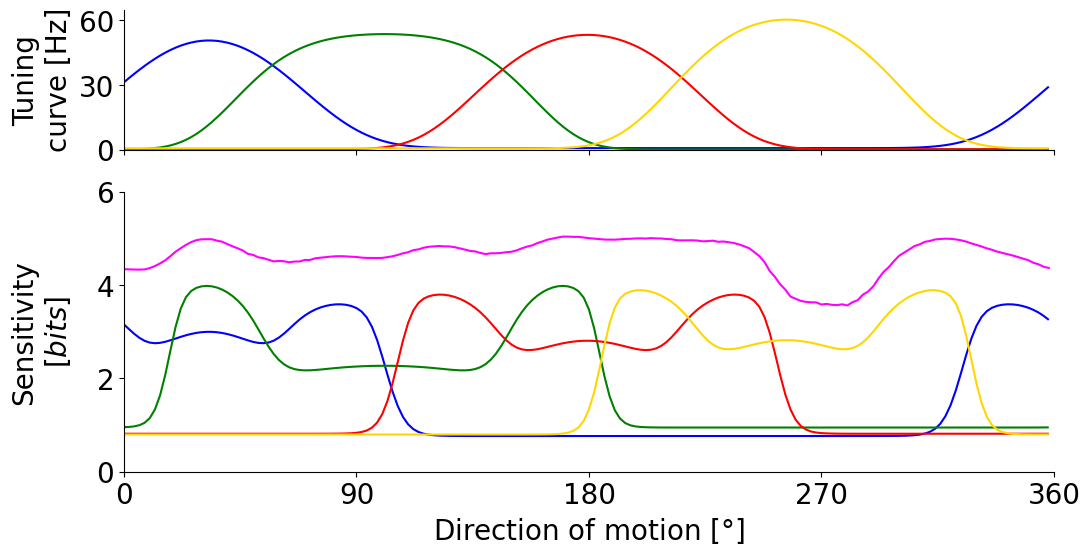

In [13]:
import matplotlib.pyplot as plt
import matplotlib.gridspec as gridspec
import numpy as np

fig = plt.figure(figsize=(12,6))

# A 2×1 subgrid matching the shape of the original lower-left panels
gs = gridspec.GridSpec(1,1)
gs0 = gs[0].subgridspec(2,1, height_ratios=(1,2))  # left column only

ax_tc2  = fig.add_subplot(gs0[0,0])   # top panel
ax_ssi2 = fig.add_subplot(gs0[1,0])   # bottom panel

# -----------------------
#   PANEL CONTENTS
# -----------------------
example_ssis = data_dict['all_ssis'][example_quads, bio_idx]
example_tcs  = data_dict['all_quad_tc'][example_quads, bio_idx]

example_single_ssis = np.array([
    ssiMod.GET_SSI_LOOP(tc)
    for tc in data_dict['all_quad_tc'][example_quads, bio_idx]
])

# --- ax_tc2 ---
i = 1  # because this is the second example panel
lc_tc = LC(np.concatenate(
    (np.tile(np.copy(stim)[None,:,None], (4,1,1)),
     np.copy(example_tcs[i])[:,:,None]/1.6),
    axis=2),
    colors=colors
)
ax_tc2.tick_params(labelsize=labelsize)
ax_ssi2.tick_params(labelsize=labelsize)

ax_tc2.set_xticks(np.arange(0,361,90), [])
ax_tc2.set_yticks(np.arange(0,61,30))
ax_tc2.set_xlim(0,360)
ax_tc2.set_ylim(0,65)
ax_tc2.add_collection(lc_tc)
ax_tc2.set_ylabel('Tuning\ncurve [Hz]', size=labelsize)
ax_tc2.yaxis.set_label_coords(-0.055, 0.5)

# ax_tc2.text(-0.1, 1.01, r'$\bf{B}$', size=textsize, transform=ax_tc2.transAxes)

# --- ax_ssi2 ---
lc_ssi = LC(np.concatenate(
    (np.tile(np.copy(stim)[None,:,None], (4,1,1)),
     np.copy(example_single_ssis[i])[:,:,None]),
    axis=2),
    colors=colors
)

ax_ssi2.set_xticks(np.arange(0,361,90))
ax_ssi2.set_yticks(np.arange(0,6.1,2))
ax_ssi2.plot(stim, example_ssis[i], color='magenta')
ax_ssi2.set_xlim(0,360)
ax_ssi2.set_ylim(0,6.0)
ax_ssi2.add_collection(lc_ssi)
ax_ssi2.set_ylabel('Sensitivity\n[$bits$]', size=labelsize)
ax_ssi2.set_xlabel(r'Direction of motion [$\degree$]', size = labelsize)
ax_ssi2.yaxis.set_label_coords(-0.055, 0.5)
# ax_ssi2.text(-0.1, 1.01, r'$\bf{?}$', size=textsize, transform=ax_ssi2.transAxes)

# plt.tight_layout()
# plt.show()
fig.savefig('C:/Users/Carlo PARIS/Desktop/Thesis/PhD presentation/Images/DSpaper_fig2.png', \
            bbox_inches = 'tight', dpi = 400)

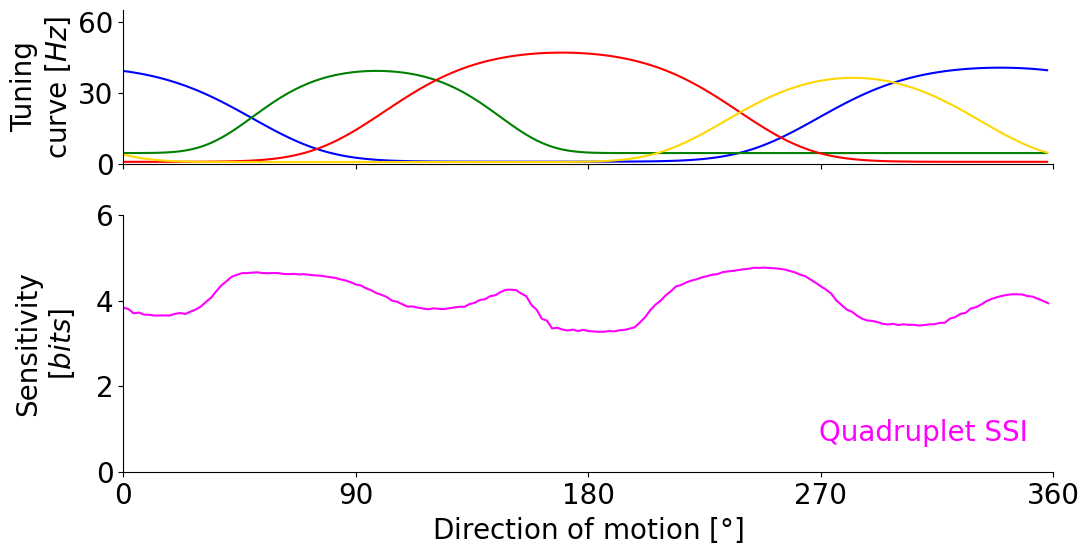

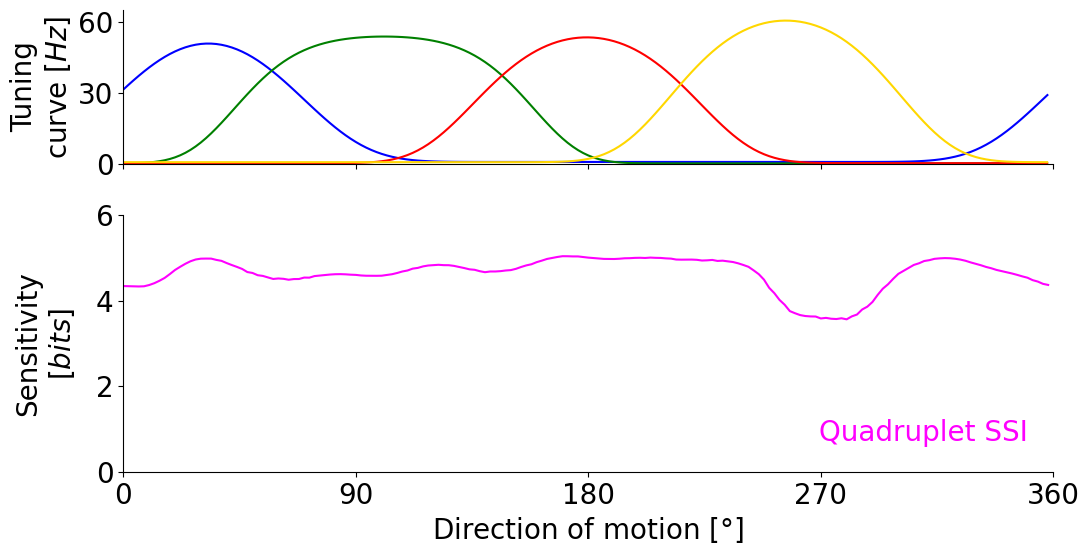

In [16]:
import matplotlib.pyplot as plt
import matplotlib.gridspec as gridspec
import numpy as np

# ------------------------- FIGURE 1 -------------------------

fig1 = plt.figure(figsize=(12, 6))
gs1 = gridspec.GridSpec(2, 1, height_ratios=[3, 5], hspace=0.25)

ax_tc1  = fig1.add_subplot(gs1[0])
ax_ssi1 = fig1.add_subplot(gs1[1])

ax_tc1.tick_params(labelsize=labelsize)
ax_ssi1.tick_params(labelsize=labelsize)
# ------------------------- FIGURE 2 -------------------------

fig2 = plt.figure(figsize=(12, 6))
gs2 = gridspec.GridSpec(2, 1, height_ratios=[3, 5], hspace=0.25)

ax_tc2  = fig2.add_subplot(gs2[0])
ax_ssi2 = fig2.add_subplot(gs2[1])

ax_tc2.tick_params(labelsize=labelsize)
ax_ssi2.tick_params(labelsize=labelsize)

# ------------------------- PLOTTING LOOP -------------------------

example_ssis = data_dict['all_ssis'][example_quads, bio_idx]
example_tcs = data_dict['all_quad_tc'][example_quads, bio_idx]

example_single_ssis = np.array([
    ssiMod.GET_SSI_LOOP(quad_tc)
    for quad_tc in data_dict['all_quad_tc'][example_quads, bio_idx]
])

plt.rcParams['xtick.labelsize'] = ticksize
plt.rcParams['ytick.labelsize'] = ticksize
plt.rc('axes', labelsize=labelsize)

# labels = [r'$\bf{A}$', r'$\bf{B}$']

for i, quad in enumerate(example_quads):

    # --- TUNING CURVE AXIS -------------------------------------------------

    ax_tc = [ax_tc1, ax_tc2][i]

    lc_tc = LC(
        np.concatenate((
            np.tile(np.copy(stim)[None, :, None], (4, 1, 1)),
            np.copy(example_tcs[i])[:, :, None] / 1.6
        ), axis=2),
        colors=colors
    )

    ax_tc.set_xticks(np.arange(0, 361, 90), [])
    ax_tc.set_yticks(np.arange(0, 61, 30))
    ax_tc.set_xlim(0, 360)
    ax_tc.set_ylim(0, 65)
    ax_tc.add_collection(lc_tc)
    ax_tc.set_ylabel('Tuning\ncurve [$Hz$]', size=labelsize)
#     ax_tc.text(-0.1, 1.01, labels[i], size=textsize, transform=ax_tc.transAxes)

    # --- SSI AXIS -----------------------------------------------------------

    ax_ssi = [ax_ssi1, ax_ssi2][i]

    lc_ssi = LC(
        np.concatenate((
            np.tile(np.copy(stim)[None, :, None], (4, 1, 1)),
            np.copy(example_single_ssis[i])[:, :, None]
        ), axis=2),
        colors=colors
    )

    ax_ssi.set_xticks(np.arange(0, 361, 90))
    ax_ssi.set_yticks(np.arange(0, 6.1, 2))
    ax_ssi.plot(stim, example_ssis[i], color='magenta', label = 'Quadruplet SSI')
#     ax_ssi.axhline(example_ssis[i].min(), color = 'deepskyblue', linestyle = 'dashed', alpha = 0.5)
#     ax_ssi.axhline(example_ssis[i].mean(), color = 'crimson', linestyle = 'dashed', alpha = 0.5)
    
    ax_ssi.set_xlim(0, 360)
    ax_ssi.set_ylim(0, 6.0)

#     ax_ssi.add_collection(lc_ssi)

    ax_ssi.yaxis.set_label_coords(-0.05, 0.5)
    ax_ssi.set_ylabel('Sensitivity\n'+r'[$bits$]', size=labelsize)
    ax_ssi.set_xlabel(r'Direction of motion [$\degree$]', size=labelsize)
    ax_ssi.legend(handlelength = 0, labelcolor = 'linecolor', frameon=0, \
                  fontsize = labelsize, loc = 'lower right')

# ------------------------- SAVE FIGURES -------------------------

# fig.savefig('C:/Users/Carlo PARIS/Desktop/Thesis/PhD presentation/Images/DSpaper_fig2.png', \
#             bbox_inches = 'tight', dpi = 400)
save_dir = 'C:/Users/Carlo PARIS/Desktop/Thesis/PhD presentation/Images/'

fig1.savefig(save_dir+'Paper_Figure_TC1_SSI1_wMin&Avg.jpg', bbox_inches='tight', dpi=400)
fig2.savefig(save_dir+'Paper_Figure_TC2_SSI2_wMin&Avg.jpg', bbox_inches='tight', dpi=400)

plt.show()
